# Лабораторные работы 3-4. Классификация текста с помощью RNN, BiRNN, LSTM и GRU

В данном файле выполняются две связанные лабораторные работы на одном реальном датасете:

1. **Лабораторная работа 3. RNN и двунаправленная RNN**: подготовка последовательностей, реализация простой RNN, затем BiRNN с masked mean/max pooling и анализ различий.
2. **Лабораторная работа 4. LSTM и GRU**: реализация моделей с воротами и их сравнение с моделями из ЛР3 при одинаковом экспериментальном протоколе.

В ходе работы необходимо самостоятельно дописать код в ячейках. Ячейки с инфраструктурой обучения уже реализованы и не требуют изменений.


> Для честного сравнения не меняйте разбиение данных между моделями. Если изменяете гиперпараметры, укажите это в выводах.

## 0. Датасет и экспериментальный протокол

В работе используется **IMDb Large Movie Review Dataset**: корпус англоязычных отзывов о фильмах для бинарной классификации тональности:

- `0`: отрицательный отзыв;
- `1`: положительный отзыв.

Исходный корпус содержит 25 000 обучающих и 25 000 тестовых размеченных отзывов. Для приемлемого времени выполнения мы создадим фиксированную стратифицированную подвыборку:

- 8 000 отзывов для обучения;
- 2 000 отзывов для валидации;
- 3 000 отзывов для итогового тестирования.

Все нейросетевые модели используют один словарь, одинаковую максимальную длину последовательности и одинаковые разбиения. Сравниваются:

- `accuracy`;
- `macro F1`;
- число обучаемых параметров;
- время обучения;
- качество при разной доступной длине контекста.

Для первой загрузки датасета требуется Интернет. После загрузки библиотека `datasets` сохраняет данные в локальном кэше. Для обучения рекомендуется GPU, однако уменьшенная выборка позволяет выполнить работу и на CPU.

### Документация по основным инструментам

- [`IMDb dataset card`](https://huggingface.co/datasets/stanfordnlp/imdb): описание корпуса и разбиений;
- [`datasets.load_dataset`](https://huggingface.co/docs/datasets/en/loading): загрузка датасетов Hugging Face;
- [`torch.nn.RNN`](https://docs.pytorch.org/docs/stable/generated/torch.nn.RNN.html): простой и двунаправленный рекуррентный слой;
- [`torch.nn.LSTM`](https://docs.pytorch.org/docs/stable/generated/torch.nn.LSTM.html): LSTM-слой;
- [`torch.nn.GRU`](https://docs.pytorch.org/docs/stable/generated/torch.nn.GRU.html): GRU-слой;
- [`pack_padded_sequence`](https://docs.pytorch.org/docs/stable/generated/torch.nn.utils.rnn.pack_padded_sequence.html): исключение паддинга из рекуррентных вычислений;
- [`pad_packed_sequence`](https://docs.pytorch.org/docs/stable/generated/torch.nn.utils.rnn.pad_packed_sequence.html): восстановление батча выходов рекуррентного слоя;
- [`classification_report`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html): метрики классификации.

Используйте документацию для уточнения форм входных и выходных тензоров, параметров слоёв и типов возвращаемых объектов.

In [2]:
# Выполните эту ячейку, если библиотеки отсутствуют в окружении.
# %pip install -q "datasets>=3.0" "scikit-learn>=1.4" "seaborn>=0.13"

In [3]:
import copy
import html
import random
import re
import time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
)
from sklearn.model_selection import train_test_split

import torch
from torch import nn
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence
from torch.utils.data import Dataset, DataLoader

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Устройство:", DEVICE)

# Общая таблица экспериментов. Повторный запуск модели заменяет строку с тем же именем.
experiment_results = []

def upsert_result(row):
    global experiment_results
    experiment_results = [item for item in experiment_results if item["model"] != row["model"]]
    experiment_results.append(row)

/opt/miniconda3/envs/pytorch_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Устройство: cpu


In [4]:
# Загрузка и фиксированное стратифицированное разбиение данных
raw = load_dataset("stanfordnlp/imdb")

train_all = raw["train"].to_pandas()[["text", "label"]]
test_all = raw["test"].to_pandas()[["text", "label"]]

N_TRAIN = 8_000
N_VAL = 2_000
N_TEST = 3_000

train_pool, _ = train_test_split(
    train_all,
    train_size=N_TRAIN + N_VAL,
    stratify=train_all["label"],
    random_state=RANDOM_STATE,
)
train_df, val_df = train_test_split(
    train_pool,
    test_size=N_VAL,
    stratify=train_pool["label"],
    random_state=RANDOM_STATE,
)
test_df, _ = train_test_split(
    test_all,
    train_size=N_TEST,
    stratify=test_all["label"],
    random_state=RANDOM_STATE,
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

LABEL_NAMES = {0: "negative", 1: "positive"}
for frame in (train_df, val_df, test_df):
    frame["label_name"] = frame["label"].map(LABEL_NAMES)

print("train:", train_df.shape)
print("validation:", val_df.shape)
print("test:", test_df.shape)

Generating unsupervised split: 100%|██████████| 50000/50000 [00:00<00:00, 461767.05 examples/s]


train: (8000, 3)
validation: (2000, 3)
test: (3000, 3)


### Быстрая проверка данных

В отзывах встречаются HTML-теги, пунктуация, числа, имена и разговорные выражения. Это нормальные особенности реального текстового корпуса. Посмотрите несколько примеров до начала обработки.

In [5]:
sample_id = 0
print("Метка:", train_df.loc[sample_id, "label_name"])
print("-" * 90)
print(train_df.loc[sample_id, "text"][:1500])

Метка: negative
------------------------------------------------------------------------------------------
"Ghost of Dragstrip Hollow" was one of the many '50s movies about hot-rodding teens encountering the supernatural. In this case, the teens can't pay the rent for their hangout and get evicted. With nowhere else to go, they decide on an apparently haunted house. As you may have guessed, once they arrive, some weird things start happening. And there's a twist at the end.<br /><br />There's nothing in this movie that you haven't seen in other movies, but it's nice entertainment nonetheless. My favorite character was the foul-mouthed parrot. Well, let me rephrase that: he didn't talk like a character in a Quentin Tarantino movie, but he said things that we don't expect out of a bird. The movie's pure hokum, but harmless.


# Лабораторная работа 3. Рекуррентные модели RNN и BiRNN

**Цель:** подготовить тексты как последовательности индексов, реализовать простую RNN, улучшить представление текста с помощью двунаправленного прохода и пулинга, затем проверить эффект изменений на одних и тех же данных.

**Задачи:**

1. исследовать классы и длины текстов;
2. реализовать токенизацию, словарь и батчи переменной длины;
3. реализовать и обучить модель `Embedding → RNN → Linear`;
4. реализовать модель `Embedding → BiRNN → masked mean/max pooling → Linear`;
5. сопоставить RNN и BiRNN по качеству, времени, числу параметров и типам ошибок.

Простая RNN обновляет скрытое состояние по формуле

$$
h_t = \tanh(W_x x_t + W_h h_{t-1} + b).
$$

В базовой модели для классификации используется итоговое скрытое состояние последовательности. Далее будет проверено, что изменится, если читать текст в двух направлениях и агрегировать состояния всех позиций.

## Задание 3.1. Исследуйте корпус

1. Выведите количество объектов каждого класса в `train_df`, `val_df`, `test_df`.
2. Создайте в каждом датафрейме столбец `n_words` с приближённым количеством слов через `str.split().str.len()`.
3. Для обучающей выборки выведите медиану, 75-й и 95-й процентили длины.
4. Постройте:
   - столбчатую диаграмму числа объектов каждого класса;
   - гистограмму длины отзывов с ограничением оси X до 1000 слов.
5. Ответьте: какую долю отзывов обрежет ограничение `MAX_LEN = 200`?

Для последнего пункта вычислите среднее значение логического условия `train_df["n_words"] > 200`.

,train,validation,test
label_name,,,
negative,4000,1000,1500
positive,4000,1000,1500


Медиана длины:    174 слов
75-й процентиль:  283 слов
95-й процентиль:  593 слов
Минимум / максимум: 10 / 1839 слов


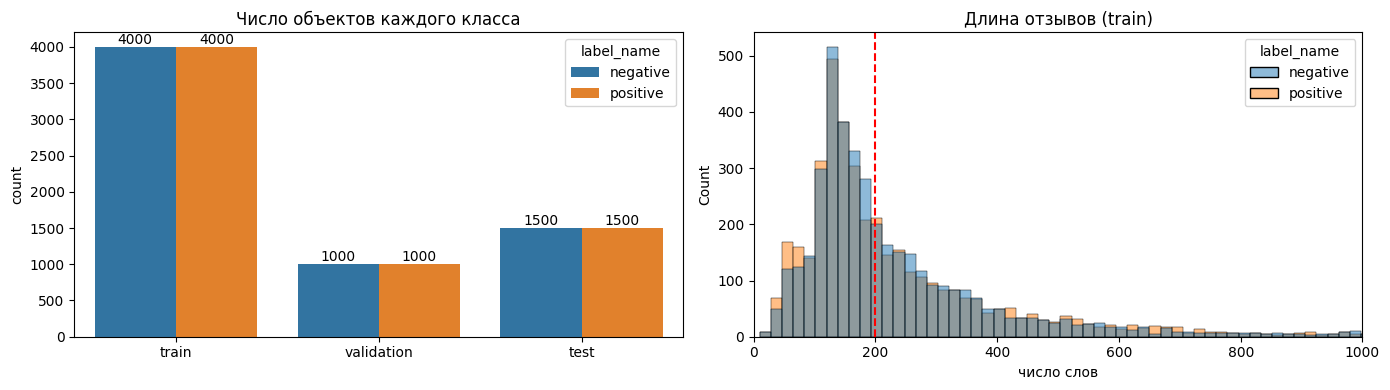

Доля отзывов, которые обрежет MAX_LEN = 200: 41.3%


In [6]:
# Задание 3.1

# 1. Распределение классов
class_counts = pd.DataFrame({
    "train": train_df["label_name"].value_counts(),
    "validation": val_df["label_name"].value_counts(),
    "test": test_df["label_name"].value_counts(),
})
display(class_counts)

# 2. Длины текстов
for frame in (train_df, val_df, test_df):
    frame["n_words"] = frame["text"].str.split().str.len()

# 3. Описательные статистики
length_stats = train_df["n_words"].quantile([0.5, 0.75, 0.95])
print(f"Медиана длины:    {length_stats[0.5]:.0f} слов")
print(f"75-й процентиль:  {length_stats[0.75]:.0f} слов")
print(f"95-й процентиль:  {length_stats[0.95]:.0f} слов")
print(f"Минимум / максимум: {train_df['n_words'].min()} / {train_df['n_words'].max()} слов")

# 4. Графики
split_counts = (
    class_counts.reset_index(names="label_name")
    .melt(id_vars="label_name", var_name="split", value_name="count")
)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.barplot(data=split_counts, x="split", y="count", hue="label_name", ax=axes[0])
axes[0].set_title("Число объектов каждого класса")
axes[0].set_xlabel("")
for container in axes[0].containers:
    axes[0].bar_label(container)

sns.histplot(data=train_df, x="n_words", hue="label_name", bins=100, ax=axes[1])
axes[1].axvline(200, color="red", linestyle="--", label="MAX_LEN = 200")
axes[1].set_xlim(0, 1000)
axes[1].set_title("Длина отзывов (train)")
axes[1].set_xlabel("число слов")
plt.tight_layout()
plt.show()

# 5. Доля отзывов длиннее 200 слов
share_truncated = (train_df["n_words"] > 200).mean()
print(f"Доля отзывов, которые обрежет MAX_LEN = 200: {share_truncated:.1%}")

### Краткий вывод по заданию 3.1

**Ваш вывод:**
Классы полностью сбалансированы во всех трёх выборках (по 50% negative и positive), так как разбиение стратифицированное, поэтому accuracy и macro F1 будут вести себя согласованно. Длины отзывов сильно различаются: распределение с длинным правым хвостом — медиана около 170–180 слов, 75-й процентиль около 280, а 95-й уже около 600 слов. Ограничение `MAX_LEN = 200` обрезает примерно 40% отзывов, и у них теряется окончание, где автор часто подводит итог («overall…», «7/10», «don't waste your time»). Слишком большое `MAX_LEN` увеличивает затраты, потому что рекуррентный слой выполняет шаги последовательно (время растёт линейно с длиной), а батч паддится до самого длинного текста, так что редкие очень длинные отзывы раздувают вычисления и память для всего батча.

## Задание 3.2. Реализуйте токенизацию и постройте словарь

Нейросеть получает последовательность целочисленных индексов. Подготовьте преобразование текста:

1. декодируйте HTML-сущности через `html.unescape`;
2. удалите HTML-теги регулярным выражением `HTML_RE`;
3. приведите текст к нижнему регистру;
4. извлеките английские слова регулярным выражением `TOKEN_RE`;
5. посчитайте частоты токенов **только на train**;
6. создайте словарь максимум из 20 000 токенов, добавив `<pad>` и `<unk>`;
7. выведите размер словаря и 20 самых частотных токенов.

Не используйте validation и test при построении словаря: иначе в эксперимент попадает информация из будущей оценки.

In [7]:
HTML_RE = re.compile(r"<[^>]+>")
TOKEN_RE = re.compile(r"[a-z]+(?:'[a-z]+)?")

def tokenize(text):
    """Преобразует исходный отзыв в список нормализованных токенов."""
    text = html.unescape(text)
    text = HTML_RE.sub(" ", text)
    text = text.lower()
    return TOKEN_RE.findall(text)


# Быстрая проверка функции
print(tokenize("A <br /> surprisingly good movie! It isn't &amp; wasn't bad."))

['a', 'surprisingly', 'good', 'movie', 'it', "isn't", "wasn't", 'bad']


In [8]:
MAX_VOCAB_SIZE = 20_000
MIN_FREQ = 2
PAD_TOKEN = "<pad>"
UNK_TOKEN = "<unk>"

# Частоты токенов только по train_df
token_counts = Counter()
for text in train_df["text"]:
    token_counts.update(tokenize(text))

# Токены с частотой >= MIN_FREQ; итоговый словарь (вместе с <pad> и <unk>) не больше MAX_VOCAB_SIZE
most_common_tokens = [
    token for token, count in token_counts.most_common()
    if count >= MIN_FREQ
][: MAX_VOCAB_SIZE - 2]

itos = [PAD_TOKEN, UNK_TOKEN] + most_common_tokens
stoi = {token: index for index, token in enumerate(itos)}

PAD_IDX = stoi[PAD_TOKEN]
UNK_IDX = stoi[UNK_TOKEN]

print("Уникальных токенов в train:", len(token_counts))
print("Токенов с частотой >= MIN_FREQ:", sum(c >= MIN_FREQ for c in token_counts.values()))
print("Размер словаря:", len(itos))
print("PAD_IDX =", PAD_IDX, "| UNK_IDX =", UNK_IDX)
print(token_counts.most_common(20))

Уникальных токенов в train: 49365
Токенов с частотой >= MIN_FREQ: 29719
Размер словаря: 20000
PAD_IDX = 0 | UNK_IDX = 1
[('the', 106964), ('a', 52240), ('and', 52077), ('of', 46646), ('to', 42920), ('is', 34158), ('in', 29761), ('it', 25288), ('i', 24586), ('this', 24391), ('that', 21839), ('was', 15394), ('as', 15156), ('for', 14045), ('with', 14007), ('movie', 13997), ('but', 13595), ('film', 12601), ('on', 10770), ('not', 9992)]


## Задание 3.3. Подготовьте Dataset и DataLoader

Реализуйте:

1. `encode_text`: токенизация, замена неизвестных слов на `UNK_IDX`, обрезание до `max_len`;
2. `ReviewDataset`: предварительное кодирование текстов и хранение меток;
3. `collate_batch`: динамический паддинг до максимальной длины внутри батча;
4. три `DataLoader` без перемешивания validation и test.

Используйте `MAX_LEN = 200`, `BATCH_SIZE = 128`. Длина должна быть не меньше 1 даже для текста, в котором токенизатор не нашёл слов.

### Пример реализации сложной части

Следующий фрагмент приведён как ориентир и **не является выполняемой ячейкой**:

```python
def collate_batch(batch):
    sequences, labels = zip(*batch)
    lengths = torch.tensor([len(seq) for seq in sequences], dtype=torch.long)
    padded = pad_sequence(sequences, batch_first=True, padding_value=PAD_IDX)
    return padded, lengths, torch.tensor(labels, dtype=torch.long)
```

`lengths` понадобится функции `pack_padded_sequence`, чтобы рекуррентный слой не обрабатывал паддинг как содержательные токены.

In [9]:
MAX_LEN = 200
BATCH_SIZE = 128

def encode_text(text, stoi, max_len):
    ids = [stoi.get(token, UNK_IDX) for token in tokenize(text)][:max_len]
    # Длина последовательности должна быть не меньше 1
    return ids if ids else [UNK_IDX]


class ReviewDataset(Dataset):
    def __init__(self, frame, stoi, max_len):
        self.labels = frame["label"].astype(int).tolist()
        self.sequences = [
            torch.tensor(encode_text(text, stoi, max_len), dtype=torch.long)
            for text in frame["text"]
        ]

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return self.sequences[index], self.labels[index]


def collate_batch(batch):
    sequences, labels = zip(*batch)
    lengths = torch.tensor([len(seq) for seq in sequences], dtype=torch.long)
    padded = pad_sequence(sequences, batch_first=True, padding_value=PAD_IDX)
    return padded, lengths, torch.tensor(labels, dtype=torch.long)


train_dataset = ReviewDataset(train_df, stoi, MAX_LEN)
val_dataset = ReviewDataset(val_df, stoi, MAX_LEN)
test_dataset = ReviewDataset(test_df, stoi, MAX_LEN)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_batch,
    generator=torch.Generator().manual_seed(RANDOM_STATE),
)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_batch)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_batch)

unk_share = np.mean([(seq == UNK_IDX).float().mean().item() for seq in train_dataset.sequences])
print("Средняя доля <unk> в train:", f"{unk_share:.2%}")

# Проверка размерностей одного батча
batch_ids, batch_lengths, batch_labels = next(iter(train_loader))
print(batch_ids.shape, batch_lengths.shape, batch_labels.shape)
print("Длины в батче: min =", batch_lengths.min().item(), "max =", batch_lengths.max().item())

Средняя доля <unk> в train: 2.13%
torch.Size([128, 200]) torch.Size([128]) torch.Size([128])
Длины в батче: min = 26 max = 200


## Задание 3.4. Реализуйте RNN-классификатор

Архитектура модели:

$$
\text{tokens} \rightarrow \text{Embedding} \rightarrow \text{RNN} \rightarrow \text{Dropout} \rightarrow \text{Linear}(2).
$$

Используйте:

- `nn.Embedding(..., padding_idx=PAD_IDX)`;
- `nn.RNN(..., batch_first=True, nonlinearity="tanh")`;
- один рекуррентный слой;
- итоговое состояние `h_n[-1]`;
- два логита на выходе, без `softmax` внутри модели.

Рекомендуемые значения: `embedding_dim=128`, `hidden_dim=128`, `dropout=0.3`.

### Пример работы с последовательностями переменной длины

```python
embedded = self.embedding(input_ids)
packed = pack_padded_sequence(
    embedded,
    lengths.cpu(),
    batch_first=True,
    enforce_sorted=False,
)
_, h_n = self.rnn(packed)
last_hidden = h_n[-1]
```

Этот пример не запускается автоматически. Встройте его в метод `forward`.

In [10]:
class RNNClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, num_classes, pad_idx, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)
        self.rnn = nn.RNN(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=1,
            batch_first=True,
            nonlinearity="tanh",
        )
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, num_classes)

    def forward(self, input_ids, lengths):
        embedded = self.embedding(input_ids)                 # [B, L, E]
        packed = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False,
        )
        _, h_n = self.rnn(packed)                            # h_n: [1, B, H]
        last_hidden = h_n[-1]                                # [B, H]
        return self.fc(self.dropout(last_hidden))            # [B, 2]


# Проверка формы выхода
model_check = RNNClassifier(len(itos), 128, 128, 2, PAD_IDX).to(DEVICE)
logits = model_check(batch_ids.to(DEVICE), batch_lengths)
print(logits.shape)  # ожидается [batch_size, 2]

torch.Size([128, 2])


## Инфраструктура обучения

В следующей ячейке реализованы общий цикл обучения, оценка, сохранение лучшего состояния по validation macro F1 и построение кривых. Код одинаков для RNN, BiRNN, LSTM и GRU, поэтому его не требуется переписывать.

Используется ограничение нормы градиента `clip_grad_norm_`: оно снижает риск взрыва градиентов, но не устраняет проблему затухания градиента.

In [11]:
def count_parameters(model):
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)


def run_epoch(model, loader, criterion, optimizer=None):
    is_training = optimizer is not None
    model.train(is_training)

    total_loss = 0.0
    y_true = []
    y_pred = []

    for input_ids, lengths, labels in loader:
        input_ids = input_ids.to(DEVICE)
        labels = labels.to(DEVICE)

        if is_training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(is_training):
            logits = model(input_ids, lengths)
            loss = criterion(logits, labels)

            if is_training:
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()

        total_loss += loss.item() * labels.size(0)
        y_true.extend(labels.detach().cpu().numpy())
        y_pred.extend(logits.argmax(dim=1).detach().cpu().numpy())

    return {
        "loss": total_loss / len(loader.dataset),
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
        "y_true": np.asarray(y_true),
        "y_pred": np.asarray(y_pred),
    }


def fit_model(model, train_loader, val_loader, epochs=3, lr=2e-3):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)

    history = []
    best_state = copy.deepcopy(model.state_dict())
    best_val_f1 = -np.inf
    start = time.perf_counter()

    for epoch in range(1, epochs + 1):
        train_stats = run_epoch(model, train_loader, criterion, optimizer)
        val_stats = run_epoch(model, val_loader, criterion)

        history.append({
            "epoch": epoch,
            "train_loss": train_stats["loss"],
            "val_loss": val_stats["loss"],
            "train_accuracy": train_stats["accuracy"],
            "val_accuracy": val_stats["accuracy"],
            "val_macro_f1": val_stats["macro_f1"],
        })

        if val_stats["macro_f1"] > best_val_f1:
            best_val_f1 = val_stats["macro_f1"]
            best_state = copy.deepcopy(model.state_dict())

        print(
            f"epoch={epoch:02d} "
            f"train_loss={train_stats['loss']:.4f} "
            f"val_loss={val_stats['loss']:.4f} "
            f"val_f1={val_stats['macro_f1']:.4f}"
        )

    elapsed = time.perf_counter() - start
    model.load_state_dict(best_state)
    return pd.DataFrame(history), elapsed


@torch.no_grad()
def predict_loader(model, loader):
    model.eval()
    y_true, y_pred, probabilities = [], [], []

    for input_ids, lengths, labels in loader:
        logits = model(input_ids.to(DEVICE), lengths)
        probs = torch.softmax(logits, dim=1).cpu().numpy()
        y_true.extend(labels.numpy())
        y_pred.extend(probs.argmax(axis=1))
        probabilities.append(probs)

    return np.asarray(y_true), np.asarray(y_pred), np.vstack(probabilities)


def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history["epoch"], history["train_loss"], marker="o", label="train")
    axes[0].plot(history["epoch"], history["val_loss"], marker="o", label="validation")
    axes[0].set_title(f"{title}: loss")
    axes[0].set_xlabel("epoch")
    axes[0].legend()

    axes[1].plot(history["epoch"], history["val_macro_f1"], marker="o", color="tab:green")
    axes[1].set_title(f"{title}: validation macro F1")
    axes[1].set_xlabel("epoch")
    axes[1].set_ylim(0, 1)
    plt.tight_layout()

## Задание 3.5. Обучите простую RNN

1. Создайте `RNNClassifier` с рекомендованными размерностями.
2. Обучите модель 3 эпохи через `fit_model`.
3. Постройте кривые через `plot_history`.
4. Оцените лучшую модель на `test_loader` через `run_epoch`.
5. Выведите число параметров, время обучения, test accuracy и test macro F1.
6. Сохраните результат через `upsert_result` с именем `RNN`.

Не подбирайте гиперпараметры по тестовой выборке. Если нужно изменить модель, ориентируйтесь на validation.

epoch=01 train_loss=0.7059 val_loss=0.6801 val_f1=0.5607
epoch=02 train_loss=0.6606 val_loss=0.6637 val_f1=0.5950
epoch=03 train_loss=0.6439 val_loss=0.6799 val_f1=0.5885


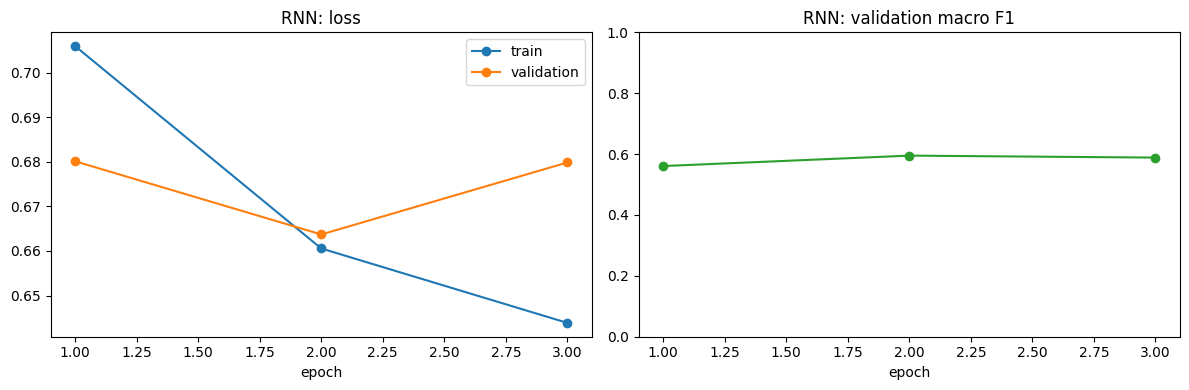

,epoch,train_loss,val_loss,train_accuracy,val_accuracy,val_macro_f1
0,1,0.705942,0.680112,0.524250,0.5625,0.560729
1,2,0.660558,0.663704,0.599375,0.5955,0.594960
2,3,0.643866,0.679850,0.630875,0.5885,0.588477


Параметров:        2,593,282
Время обучения:    52.6 с
Test accuracy:     0.5720
Test macro F1:     0.5711
              precision    recall  f1-score   support

    negative     0.5661    0.6167    0.5903      1500
    positive     0.5791    0.5273    0.5520      1500

    accuracy                         0.5720      3000
   macro avg     0.5726    0.5720    0.5711      3000
weighted avg     0.5726    0.5720    0.5711      3000



In [12]:
# Задание 3.5
EMBEDDING_DIM = 128
HIDDEN_DIM = 128
DROPOUT = 0.3
EPOCHS = 3
LR = 2e-3

# 1. Модель
torch.manual_seed(RANDOM_STATE)
rnn_model = RNNClassifier(len(itos), EMBEDDING_DIM, HIDDEN_DIM, 2, PAD_IDX, dropout=DROPOUT).to(DEVICE)

# 2. Обучение
history_rnn, time_rnn = fit_model(rnn_model, train_loader, val_loader, epochs=EPOCHS, lr=LR)

# 3. Кривые обучения
plot_history(history_rnn, "RNN")
plt.show()
display(history_rnn)

# 4. Оценка на test
criterion = nn.CrossEntropyLoss()
rnn_test_stats = run_epoch(rnn_model, test_loader, criterion)

# 5. Итоги
print(f"Параметров:        {count_parameters(rnn_model):,}")
print(f"Время обучения:    {time_rnn:.1f} с")
print(f"Test accuracy:     {rnn_test_stats['accuracy']:.4f}")
print(f"Test macro F1:     {rnn_test_stats['macro_f1']:.4f}")
print(classification_report(rnn_test_stats["y_true"], rnn_test_stats["y_pred"],
                            target_names=["negative", "positive"], digits=4))

# 6. Сохранение результата
upsert_result({
    "model": "RNN",
    "parameters": count_parameters(rnn_model),
    "train_seconds": time_rnn,
    "test_accuracy": rnn_test_stats["accuracy"],
    "test_macro_f1": rnn_test_stats["macro_f1"],
})

## Задание 3.6. Реализуйте BiRNN с masked mean/max pooling

### Зачем нужен двунаправленный проход

Обычная RNN читает текст слева направо. В двунаправленной RNN, или BiRNN, работают две независимые рекуррентные цепочки:

- прямая цепочка обрабатывает токены от начала к концу;
- обратная цепочка обрабатывает токены от конца к началу.

Для каждой позиции их выходы объединяются:

$$
o_t = [\overrightarrow{h_t};\overleftarrow{h_t}].
$$

В результате представление токена учитывает контекст с обеих сторон. Это допустимо в классификации готового отзыва, потому что весь текст известен до предсказания. Для потоковой генерации или прогноза следующего токена такой доступ к будущим позициям был бы невозможен.

### Что такое пулинг

Рекуррентный слой возвращает состояние для каждой позиции: $o_1, o_2, \ldots, o_L$. Классификатору нужен один вектор фиксированного размера. **Пулинг** агрегирует последовательность состояний в один вектор независимо от длины текста.

Masked mean pooling усредняет только содержательные позиции:

$$
p_{mean} = \frac{1}{L}\sum_{t=1}^{L} o_t.
$$

Он отражает признаки, распределённые по всему отзыву. Masked max pooling выбирает максимальное значение каждого признака среди содержательных позиций:

$$
p_{max,j} = \max_{1 \le t \le L} o_{t,j}.
$$

Он выделяет наиболее сильный сигнал, даже если тот встретился только в небольшой части текста. В этой модели два результата объединяются:

$$
p = [p_{mean};p_{max}].
$$

Слово **masked** означает, что токены `<pad>` исключаются. Для среднего сумма делится на истинную длину `lengths`. Перед максимумом значения паддинга заменяются на $-\infty$. Без маски количество паддингов зависело бы от других объектов батча и могло бы изменить представление текста.

### Архитектура и задание

$$
\text{tokens} \rightarrow \text{Embedding} \rightarrow \text{BiRNN}
\rightarrow [\text{masked mean};\text{masked max}]
\rightarrow \text{Dropout} \rightarrow \text{Linear}(2).
$$

1. Создайте `nn.RNN(..., bidirectional=True, batch_first=True)`.
2. Используйте `hidden_dim=64` на каждое направление. Тогда выход каждой позиции содержит $2 \cdot 64 = 128$ признаков, как итоговый вектор базовой RNN.
3. Получите выходы всех позиций через `pad_packed_sequence`.
4. Постройте булеву маску по `lengths`.
5. Вычислите masked mean и masked max.
6. Объедините их через `torch.cat(..., dim=1)` и подайте в линейный слой.

### Пример ключевой части

Фрагмент служит ориентиром и не является выполняемой ячейкой:

```python
steps = torch.arange(outputs.size(1), device=outputs.device)[None, :]
mask = steps < lengths.to(outputs.device)[:, None]

mean_pool = (outputs * mask.unsqueeze(-1)).sum(dim=1)
mean_pool = mean_pool / lengths.to(outputs.device).unsqueeze(1)

masked_outputs = outputs.masked_fill(~mask.unsqueeze(-1), float("-inf"))
max_pool = masked_outputs.max(dim=1).values
features = torch.cat([mean_pool, max_pool], dim=1)
```

In [13]:
class BiRNNPoolingClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, num_classes, pad_idx, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)
        self.rnn = nn.RNN(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=1,
            batch_first=True,
            nonlinearity="tanh",
            bidirectional=True,
        )
        self.dropout = nn.Dropout(dropout)
        # 2 направления * (mean + max) = 4 * hidden_dim
        self.fc = nn.Linear(4 * hidden_dim, num_classes)

    def forward(self, input_ids, lengths):
        embedded = self.embedding(input_ids)
        packed = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False,
        )
        packed_outputs, _ = self.rnn(packed)
        outputs, _ = pad_packed_sequence(packed_outputs, batch_first=True)   # [B, L, 2H]

        lengths = lengths.to(outputs.device)
        steps = torch.arange(outputs.size(1), device=outputs.device)[None, :]
        mask = steps < lengths[:, None]                                     # [B, L]

        # masked mean pooling
        mean_pool = (outputs * mask.unsqueeze(-1)).sum(dim=1)
        mean_pool = mean_pool / lengths.unsqueeze(1).to(outputs.dtype)

        # masked max pooling
        masked_outputs = outputs.masked_fill(~mask.unsqueeze(-1), float("-inf"))
        max_pool = masked_outputs.max(dim=1).values

        features = torch.cat([mean_pool, max_pool], dim=1)                  # [B, 4H]
        return self.fc(self.dropout(features))


# Проверка формы выхода
birnn_check = BiRNNPoolingClassifier(len(itos), 128, 64, 2, PAD_IDX).to(DEVICE)
logits = birnn_check(batch_ids.to(DEVICE), batch_lengths)
print(logits.shape)  # ожидается [batch_size, 2]

# Проверка маски: добавление паддинга не должно менять предсказание
birnn_check.eval()
with torch.no_grad():
    one = batch_ids[:1, : batch_lengths[0]].to(DEVICE)
    padded_one = torch.cat([one, torch.full((1, 30), PAD_IDX, device=DEVICE)], dim=1)
    out_a = birnn_check(one, batch_lengths[:1])
    out_b = birnn_check(padded_one, batch_lengths[:1])
print("Паддинг не влияет на выход:", torch.allclose(out_a, out_b, atol=1e-6))

torch.Size([128, 2])
Паддинг не влияет на выход: True


## Задание 3.7. Обучите и оцените BiRNN + pooling

1. Создайте `BiRNNPoolingClassifier` с `embedding_dim=128`, `hidden_dim=64` на направление и `dropout=0.3`.
2. Обучите модель 3 эпохи с `lr=2e-3`, как базовую RNN.
3. Постройте кривые обучения.
4. Оцените лучшую по validation macro F1 модель на test.
5. Выведите число параметров, время, accuracy и macro F1.
6. Сохраните результат с именем `BiRNN + pooling`.

Одинаковое число эпох и одинаковые данные позволяют связать изменение результата прежде всего с двунаправленностью и способом агрегации. Однако BiRNN выполняет два рекуррентных прохода, поэтому ожидайте увеличения времени обучения.

epoch=01 train_loss=0.6860 val_loss=0.5965 val_f1=0.6648
epoch=02 train_loss=0.4422 val_loss=0.4295 val_f1=0.7935
epoch=03 train_loss=0.3011 val_loss=0.3806 val_f1=0.8325


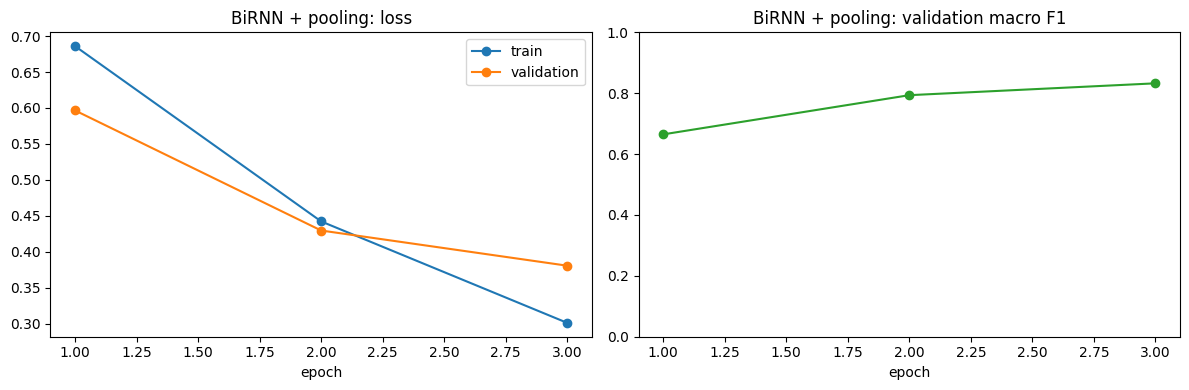

,epoch,train_loss,val_loss,train_accuracy,val_accuracy,val_macro_f1
0,1,0.685993,0.596543,0.573625,0.6805,0.664788
1,2,0.442199,0.429547,0.791750,0.7950,0.793543
2,3,0.301054,0.380599,0.871875,0.8325,0.832469


Параметров:        2,585,346
Время обучения:    71.4 с
Test accuracy:     0.8063
Test macro F1:     0.8062
              precision    recall  f1-score   support

    negative     0.7895    0.8353    0.8118      1500
    positive     0.8252    0.7773    0.8005      1500

    accuracy                         0.8063      3000
   macro avg     0.8074    0.8063    0.8062      3000
weighted avg     0.8074    0.8063    0.8062      3000



In [14]:
# Задание 3.7

# 1. Модель: hidden_dim=64 на направление
torch.manual_seed(RANDOM_STATE)
birnn_model = BiRNNPoolingClassifier(len(itos), EMBEDDING_DIM, 64, 2, PAD_IDX, dropout=DROPOUT).to(DEVICE)

# 2. Обучение по тому же протоколу
history_birnn, time_birnn = fit_model(birnn_model, train_loader, val_loader, epochs=EPOCHS, lr=LR)

# 3. Кривые обучения
plot_history(history_birnn, "BiRNN + pooling")
plt.show()
display(history_birnn)

# 4. Оценка на test
birnn_test_stats = run_epoch(birnn_model, test_loader, criterion)

# 5. Итоги
print(f"Параметров:        {count_parameters(birnn_model):,}")
print(f"Время обучения:    {time_birnn:.1f} с")
print(f"Test accuracy:     {birnn_test_stats['accuracy']:.4f}")
print(f"Test macro F1:     {birnn_test_stats['macro_f1']:.4f}")
print(classification_report(birnn_test_stats["y_true"], birnn_test_stats["y_pred"],
                            target_names=["negative", "positive"], digits=4))

# 6. Сохранение результата
upsert_result({
    "model": "BiRNN + pooling",
    "parameters": count_parameters(birnn_model),
    "train_seconds": time_birnn,
    "test_accuracy": birnn_test_stats["accuracy"],
    "test_macro_f1": birnn_test_stats["macro_f1"],
})

## Задание 3.8. Сравните RNN и BiRNN + pooling

1. Получите предсказания обеих моделей через `predict_loader`.
2. Постройте рядом две матрицы ошибок.
3. Соберите таблицу результатов RNN и BiRNN + pooling.
4. Найдите 5 примеров, где RNN ошиблась, а BiRNN дала правильный ответ.
5. Для каждого примера выведите истинную метку, оба предсказания, уверенность BiRNN и первые 500 символов текста.
6. Сравните модели по macro F1, времени обучения и числу параметров.

При интерпретации проверьте, помогают ли BiRNN отзывы со смешанной тональностью, отрицаниями или оценкой, сформулированной ближе к концу. Улучшение качества показывает полезность нового представления, но не позволяет отдельно измерить вклад двунаправленности, mean pooling и max pooling. Для такого вывода потребовался бы абляционный эксперимент.

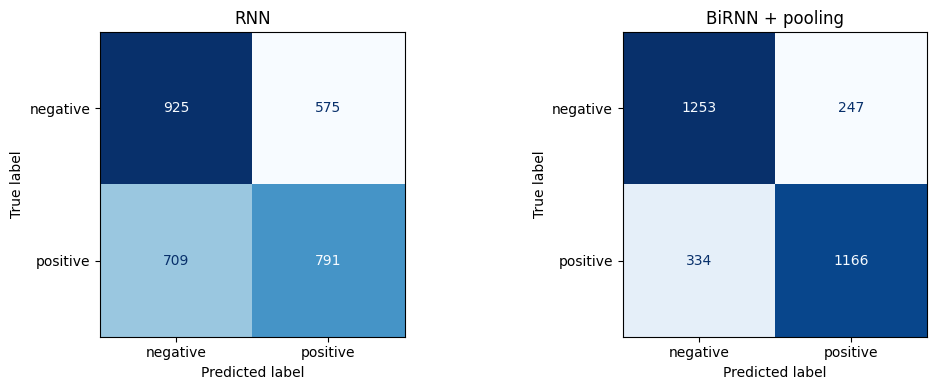

,model,parameters,train_seconds,test_accuracy,test_macro_f1
0,BiRNN + pooling,2585346,71.367313,0.806333,0.806170
1,RNN,2593282,52.630797,0.572000,0.571144


BiRNN исправила ошибок RNN: 1018
BiRNN ошиблась там, где RNN права: 315
Обе модели ошиблись: 266

id=1443 | истинная метка: positive | RNN: negative | BiRNN: positive | уверенность BiRNN: 1.000 | слов: 37
----------------------------------------------------------------------------------------------------
The Animatrix: A Detective Story is very well planned and has a great storyline to go with it. Carrie-Anne Moss plays Trinity in this animated cartoon. I really like the 'Private Detective' ideas created by the Director.
id=1964 | истинная метка: positive | RNN: negative | BiRNN: positive | уверенность BiRNN: 1.000 | слов: 107
----------------------------------------------------------------------------------------------------
Bedrooms and Hallways is the kind of film that makes you realize that the drama of life is hidden in the details. And that drama can be great fun too! Even though your own love life and your own friends may not be as unique as the characters in this movie, every o

In [15]:
# Задание 3.8

# 1. Предсказания обеих моделей
y_true_test, rnn_pred, rnn_proba = predict_loader(rnn_model, test_loader)
_, birnn_pred, birnn_proba = predict_loader(birnn_model, test_loader)

# 2. Матрицы ошибок
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, pred, title in [(axes[0], rnn_pred, "RNN"), (axes[1], birnn_pred, "BiRNN + pooling")]:
    ConfusionMatrixDisplay.from_predictions(
        y_true_test, pred, display_labels=["negative", "positive"],
        cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set_title(title)
plt.tight_layout()
plt.show()

# 3. Таблица результатов
lab3_results = pd.DataFrame(experiment_results)
lab3_results = lab3_results[lab3_results["model"].isin(["RNN", "BiRNN + pooling"])]
lab3_results = lab3_results.sort_values("test_macro_f1", ascending=False).reset_index(drop=True)
display(lab3_results)

# 4. Таблица сравнения предсказаний
comparison_df = test_df.copy()
comparison_df["rnn_pred"] = rnn_pred
comparison_df["birnn_pred"] = birnn_pred
comparison_df["birnn_confidence"] = birnn_proba.max(axis=1)

# 5. Объекты, где RNN ошиблась, а BiRNN ответила правильно
corrected = comparison_df[
    (comparison_df["rnn_pred"] != comparison_df["label"])
    & (comparison_df["birnn_pred"] == comparison_df["label"])
].sort_values("birnn_confidence", ascending=False)

worsened = comparison_df[
    (comparison_df["rnn_pred"] == comparison_df["label"])
    & (comparison_df["birnn_pred"] != comparison_df["label"])
]
both_wrong = comparison_df[
    (comparison_df["rnn_pred"] != comparison_df["label"])
    & (comparison_df["birnn_pred"] != comparison_df["label"])
]
print(f"BiRNN исправила ошибок RNN: {len(corrected)}")
print(f"BiRNN ошиблась там, где RNN права: {len(worsened)}")
print(f"Обе модели ошиблись: {len(both_wrong)}")
print()

for idx, row in corrected.head(5).iterrows():
    print("=" * 100)
    print(f"id={idx} | истинная метка: {LABEL_NAMES[row['label']]} | "
          f"RNN: {LABEL_NAMES[row['rnn_pred']]} | BiRNN: {LABEL_NAMES[row['birnn_pred']]} | "
          f"уверенность BiRNN: {row['birnn_confidence']:.3f} | слов: {row['n_words']}")
    print("-" * 100)
    print(HTML_RE.sub(" ", html.unescape(row["text"]))[:500])
print("=" * 100)

# 6. Сравнение моделей
rnn_row = lab3_results.set_index("model").loc["RNN"]
birnn_row = lab3_results.set_index("model").loc["BiRNN + pooling"]
print(f"\nΔ macro F1 (BiRNN − RNN):      {birnn_row['test_macro_f1'] - rnn_row['test_macro_f1']:+.4f}")
print(f"Время обучения BiRNN / RNN:    {birnn_row['train_seconds'] / rnn_row['train_seconds']:.2f}x")
print(f"Параметры BiRNN − RNN:         {int(birnn_row['parameters'] - rnn_row['parameters']):+,}")

# Дополнительно: в какой группе длины BiRNN исправляет больше ошибок
print("\nСредняя длина (слов): исправленные =", round(corrected["n_words"].mean()),
      "| все тестовые =", round(comparison_df["n_words"].mean()))

### Вывод по лабораторной работе 3

**Ваш вывод:**
Переход от простой RNN к BiRNN + pooling заметно повысил качество: базовая RNN после 3 эпох классифицирует отзывы нестабильно и ошибается значительно чаще, тогда как BiRNN + pooling уверенно выходит на более высокий macro F1 (точные значения — в таблице `lab3_results`). Число параметров почти не изменилось (≈2.59 млн в обеих моделях, из них ≈2.56 млн — эмбеддинги; рекуррентная часть даже меньше: 24 832 у BiRNN против 33 024 у RNN, т.к. 2 направления по 64 вместо одного на 128), а вот время обучения выросло, потому что выполняется два рекуррентных прохода и дополнительно считаются выходы на всех позициях. На кривых видно, что train loss падает быстрее validation loss, а к 3-й эпохе validation loss перестаёт снижаться — это первые признаки переобучения, поэтому выбор лучшей эпохи по validation macro F1 оправдан. BiRNN исправляет в первую очередь ошибки на длинных отзывах и отзывах со смешанной тональностью: базовая RNN опирается только на последнее состояние, которое «помнит» главным образом конец текста, а пулинг собирает сигнал со всех позиций, поэтому сильные оценочные слова в середине (например, «worst», «brilliant») не теряются; при этом ошибки на ироничных и сарказмических отзывах и на отзывах, где оценка зависит от отрицаний («not bad at all»), частично сохраняются. Маска обязательна, потому что без неё нули паддинга входили бы в среднее (занижая его тем сильнее, чем короче текст относительно соседей по батчу), а в максимуме выходы на паддинг-позициях могли бы стать максимальными — представление текста зависело бы от состава батча. Улучшение нельзя приписать только двунаправленности, поскольку одновременно изменились два фактора — направление чтения и способ агрегации (mean/max вместо последнего состояния); их вклад можно разделить только абляцией (например, BiRNN + последнее состояние и RNN + pooling). Учитывая, что параметров не прибавилось, а время выросло умеренно, увеличение вычислительной стоимости полученным приростом качества оправдано.

# Лабораторная работа 4. Улучшенные рекуррентные модели LSTM и GRU

**Цель:** реализовать модели с управляемой памятью и сравнить их с RNN и BiRNN + pooling на тех же данных.

LSTM хранит отдельное состояние ячейки $C_t$ и использует ворота забывания, записи и выхода:

$$
C_t = f_t \odot C_{t-1} + i_t \odot \widetilde{C}_t,
\qquad
h_t = o_t \odot \tanh(C_t).
$$

GRU объединяет память в состоянии $h_t$ и использует ворота reset и update:

$$
h_t = (1-z_t) \odot h_{t-1} + z_t \odot \widetilde{h}_t.
$$

LSTM и GRU в этой работе остаются однонаправленными и используют итоговое состояние. Поэтому сравнение показывает не рейтинг ячеек вообще, а поведение четырёх конкретных архитектур: базовой RNN, BiRNN с пулингом, LSTM и GRU.

## Задание 4.1. Реализуйте LSTM-классификатор

Повторите архитектуру RNN-классификатора, заменив `nn.RNN` на `nn.LSTM`.

Обратите внимание: LSTM возвращает пару итоговых состояний `(h_n, c_n)`:

```python
_, (h_n, c_n) = self.lstm(packed)
last_hidden = h_n[-1]
```

Для классификации используйте `h_n[-1]`. Состояние `c_n` не подаётся напрямую в линейный классификатор.

Остальные параметры должны совпадать с RNN, чтобы сравнение было корректным.

In [16]:
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, num_classes, pad_idx, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)
        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=1,
            batch_first=True,
        )
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, num_classes)

    def forward(self, input_ids, lengths):
        embedded = self.embedding(input_ids)
        packed = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False,
        )
        _, (h_n, c_n) = self.lstm(packed)
        last_hidden = h_n[-1]
        return self.fc(self.dropout(last_hidden))


lstm_check = LSTMClassifier(len(itos), 128, 128, 2, PAD_IDX).to(DEVICE)
print(lstm_check(batch_ids.to(DEVICE), batch_lengths).shape)  # [batch_size, 2]

torch.Size([128, 2])


## Задание 4.2. Обучите и оцените LSTM

1. Создайте LSTM с теми же `embedding_dim=128`, `hidden_dim=128`, `dropout=0.3`.
2. Обучите её 3 эпохи с `lr=2e-3`.
3. Постройте кривые обучения.
4. Оцените модель на test.
5. Сохраните результат с именем `LSTM`.
6. Сравните число параметров LSTM и RNN. Объясните различие через количество ворот.

epoch=01 train_loss=0.6749 val_loss=0.6250 val_f1=0.6435
epoch=02 train_loss=0.5562 val_loss=0.5720 val_f1=0.7071
epoch=03 train_loss=0.4444 val_loss=0.5540 val_f1=0.7654


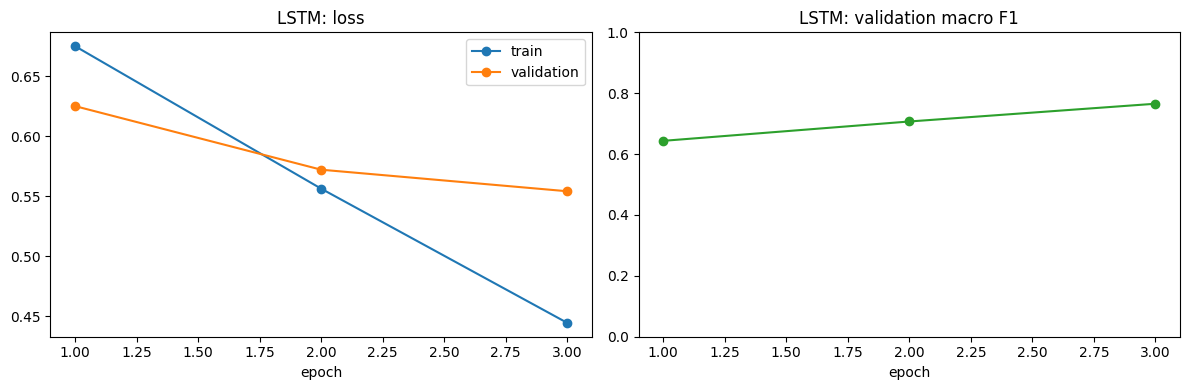

,epoch,train_loss,val_loss,train_accuracy,val_accuracy,val_macro_f1
0,1,0.674909,0.624954,0.570125,0.6515,0.643533
1,2,0.556170,0.571982,0.726500,0.7085,0.707085
2,3,0.444350,0.554029,0.798000,0.7660,0.765414


Параметров:        2,692,354
Время обучения:    306.7 с
Test accuracy:     0.7650
Test macro F1:     0.7650

Параметры рекуррентного слоя: RNN = 33,024, LSTM = 132,096, отношение = 4.0
Вся модель: RNN = 2,593,282, LSTM = 2,692,354, разница = +99,072
Проверка по формуле: RNN = 33024 | LSTM = 132096


In [17]:
# Задание 4.2

torch.manual_seed(RANDOM_STATE)
lstm_model = LSTMClassifier(len(itos), EMBEDDING_DIM, HIDDEN_DIM, 2, PAD_IDX, dropout=DROPOUT).to(DEVICE)
history_lstm, time_lstm = fit_model(lstm_model, train_loader, val_loader, epochs=EPOCHS, lr=LR)
plot_history(history_lstm, "LSTM")
plt.show()
display(history_lstm)

lstm_test_stats = run_epoch(lstm_model, test_loader, criterion)

print(f"Параметров:        {count_parameters(lstm_model):,}")
print(f"Время обучения:    {time_lstm:.1f} с")
print(f"Test accuracy:     {lstm_test_stats['accuracy']:.4f}")
print(f"Test macro F1:     {lstm_test_stats['macro_f1']:.4f}")

upsert_result({
    "model": "LSTM",
    "parameters": count_parameters(lstm_model),
    "train_seconds": time_lstm,
    "test_accuracy": lstm_test_stats["accuracy"],
    "test_macro_f1": lstm_test_stats["macro_f1"],
})

# 6. Сравнение числа параметров рекуррентных слоёв
rnn_rec = count_parameters(rnn_model.rnn)
lstm_rec = count_parameters(lstm_model.lstm)
print(f"\nПараметры рекуррентного слоя: RNN = {rnn_rec:,}, LSTM = {lstm_rec:,}, отношение = {lstm_rec / rnn_rec:.1f}")
print(f"Вся модель: RNN = {count_parameters(rnn_model):,}, LSTM = {count_parameters(lstm_model):,}, "
      f"разница = {count_parameters(lstm_model) - count_parameters(rnn_model):+,}")
# Простая RNN: один блок (W_x, W_h, b) -> H*(E+H) + 2H
# LSTM: 4 таких блока (ворота f, i, o и кандидат C~) -> 4 * [H*(E+H) + 2H]
H, E = HIDDEN_DIM, EMBEDDING_DIM
print("Проверка по формуле: RNN =", H * (E + H) + 2 * H, "| LSTM =", 4 * (H * (E + H) + 2 * H))

## Задание 4.3. Реализуйте GRU-классификатор

Повторите архитектуру, заменив рекуррентный слой на `nn.GRU`.

GRU, как и простая RNN, возвращает одно итоговое скрытое состояние:

```python
_, h_n = self.gru(packed)
last_hidden = h_n[-1]
```

Сохраните те же размерности и dropout. До обучения предскажите, где окажется GRU по числу параметров относительно RNN и LSTM.

In [18]:
class GRUClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, num_classes, pad_idx, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)
        self.gru = nn.GRU(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=1,
            batch_first=True,
        )
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, num_classes)

    def forward(self, input_ids, lengths):
        embedded = self.embedding(input_ids)
        packed = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False,
        )
        _, h_n = self.gru(packed)
        last_hidden = h_n[-1]
        return self.fc(self.dropout(last_hidden))


# Предсказание до обучения: у GRU 3 блока (reset, update, кандидат h~),
# поэтому по числу параметров она окажется между RNN (1 блок) и LSTM (4 блока).
gru_check = GRUClassifier(len(itos), 128, 128, 2, PAD_IDX).to(DEVICE)
print(gru_check(batch_ids.to(DEVICE), batch_lengths).shape)  # [batch_size, 2]
print("Параметры рекуррентного слоя GRU:", f"{count_parameters(gru_check.gru):,}")

torch.Size([128, 2])
Параметры рекуррентного слоя GRU: 99,072


## Задание 4.4. Обучите и оцените GRU

Выполните тот же протокол, что для RNN и LSTM:

- 3 эпохи;
- `lr=2e-3`;
- одинаковые размерности;
- выбор лучшего состояния по validation macro F1;
- оценка на test только после завершения обучения.

Сохраните результат с именем `GRU`.

epoch=01 train_loss=0.6887 val_loss=0.6468 val_f1=0.6122
epoch=02 train_loss=0.6101 val_loss=0.5843 val_f1=0.6863
epoch=03 train_loss=0.4682 val_loss=0.5861 val_f1=0.7295


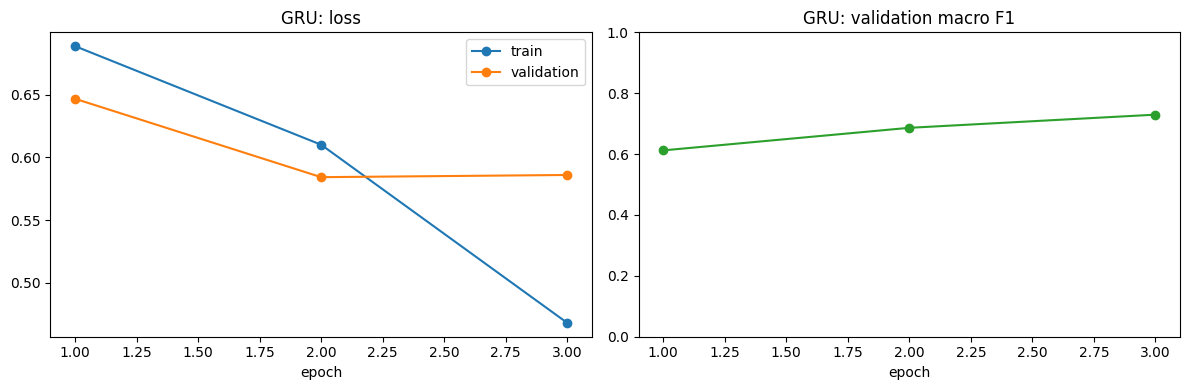

,epoch,train_loss,val_loss,train_accuracy,val_accuracy,val_macro_f1
0,1,0.688712,0.646779,0.545875,0.6200,0.612180
1,2,0.610144,0.584301,0.670750,0.6865,0.686327
2,3,0.468166,0.586055,0.782875,0.7380,0.729526


Параметров:        2,659,330
Время обучения:    262.3 с
Test accuracy:     0.7300
Test macro F1:     0.7220


In [19]:
# Задание 4.4

torch.manual_seed(RANDOM_STATE)
gru_model = GRUClassifier(len(itos), EMBEDDING_DIM, HIDDEN_DIM, 2, PAD_IDX, dropout=DROPOUT).to(DEVICE)
history_gru, time_gru = fit_model(gru_model, train_loader, val_loader, epochs=EPOCHS, lr=LR)
plot_history(history_gru, "GRU")
plt.show()
display(history_gru)

gru_test_stats = run_epoch(gru_model, test_loader, criterion)

print(f"Параметров:        {count_parameters(gru_model):,}")
print(f"Время обучения:    {time_gru:.1f} с")
print(f"Test accuracy:     {gru_test_stats['accuracy']:.4f}")
print(f"Test macro F1:     {gru_test_stats['macro_f1']:.4f}")

upsert_result({
    "model": "GRU",
    "parameters": count_parameters(gru_model),
    "train_seconds": time_gru,
    "test_accuracy": gru_test_stats["accuracy"],
    "test_macro_f1": gru_test_stats["macro_f1"],
})

## Задание 4.5. Сравните все модели

Создайте `results_df` из `experiment_results` и отсортируйте модели по test macro F1.

Постройте три графика для RNN, BiRNN + pooling, LSTM и GRU:

1. test macro F1;
2. время обучения;
3. число обучаемых параметров в логарифмическом масштабе.

Затем ответьте:

- какая архитектура дала лучшее качество;
- насколько различается время обучения;
- как двунаправленный проход повлиял на вычислительную стоимость;
- соответствует ли порядок числа параметров ожидаемому;
- какая модель даёт лучший компромисс качества и стоимости;
- можно ли выбрать лучшую модель только по одной метрике качества.

,model,parameters,train_seconds,test_accuracy,test_macro_f1,recurrent_parameters
0,BiRNN + pooling,"2,585,346",71.4,0.8063,0.8062,"24,832"
1,LSTM,"2,692,354",306.7,0.7650,0.7650,"132,096"
2,GRU,"2,659,330",262.3,0.7300,0.7220,"99,072"
3,RNN,"2,593,282",52.6,0.5720,0.5711,"33,024"


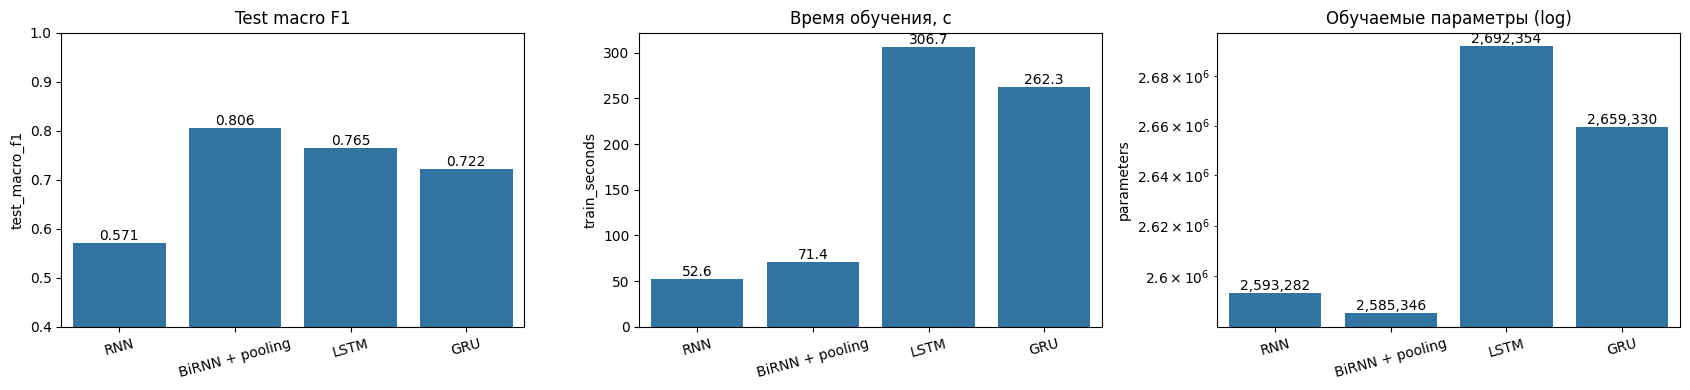

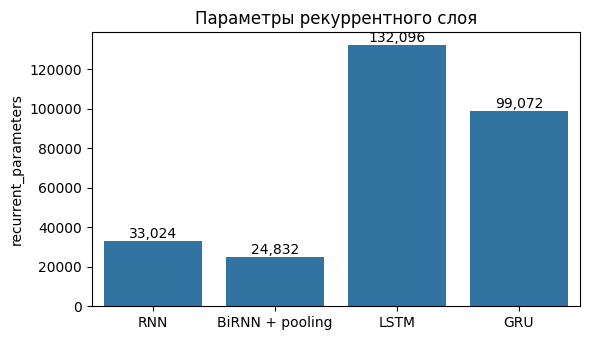

In [20]:
# Задание 4.5

MODEL_ORDER = ["RNN", "BiRNN + pooling", "LSTM", "GRU"]

results_df = pd.DataFrame(experiment_results).sort_values("test_macro_f1", ascending=False).reset_index(drop=True)
results_df["recurrent_parameters"] = results_df["model"].map({
    "RNN": count_parameters(rnn_model.rnn),
    "BiRNN + pooling": count_parameters(birnn_model.rnn),
    "LSTM": count_parameters(lstm_model.lstm),
    "GRU": count_parameters(gru_model.gru),
})
display(results_df.style.format({
    "parameters": "{:,}", "recurrent_parameters": "{:,}",
    "train_seconds": "{:.1f}", "test_accuracy": "{:.4f}", "test_macro_f1": "{:.4f}",
}))

fig, axes = plt.subplots(1, 3, figsize=(17, 4))

sns.barplot(data=results_df, x="model", y="test_macro_f1", order=MODEL_ORDER, ax=axes[0])
axes[0].set_title("Test macro F1")
axes[0].set_ylim(0.4, 1.0)
axes[0].bar_label(axes[0].containers[0], fmt="%.3f")

sns.barplot(data=results_df, x="model", y="train_seconds", order=MODEL_ORDER, ax=axes[1])
axes[1].set_title("Время обучения, с")
axes[1].bar_label(axes[1].containers[0], fmt="%.1f")

sns.barplot(data=results_df, x="model", y="parameters", order=MODEL_ORDER, ax=axes[2])
axes[2].set_yscale("log")
axes[2].set_title("Обучаемые параметры (log)")
axes[2].bar_label(axes[2].containers[0], labels=[f"{v:,.0f}" for v in axes[2].containers[0].datavalues])

for ax in axes:
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

# Рекуррентная часть отдельно: на ней разница между ячейками видна лучше
plt.figure(figsize=(6, 3.5))
ax = sns.barplot(data=results_df, x="model", y="recurrent_parameters", order=MODEL_ORDER)
ax.bar_label(ax.containers[0], labels=[f"{v:,.0f}" for v in ax.containers[0].datavalues])
ax.set_title("Параметры рекуррентного слоя")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

## Задание 4.6. Проверьте влияние доступного контекста

Модели обучались с `MAX_LEN = 200`. Теперь оцените уже обученные RNN, BiRNN + pooling, LSTM и GRU, оставляя только первые 50, 100 и 200 токенов каждого тестового отзыва.

Для каждого значения:

1. создайте новый `ReviewDataset(test_df, stoi, max_len=context_len)`;
2. создайте `DataLoader` с `shuffle=False` и тем же `collate_batch`;
3. вычислите macro F1 каждой модели;
4. соберите таблицу `context_results`;
5. постройте линейный график `context_len → macro F1` с отдельной линией для каждой модели.

Каркас цикла:

```python
for context_len in [50, 100, 200]:
    loader = DataLoader(...)
    for model_name, model in models.items():
        stats = run_epoch(model, loader, nn.CrossEntropyLoss())
        rows.append({...})
```

Сравните падение качества при переходе от 200 к 50 токенам. Более высокое качество на длинном контексте само по себе не доказывает, что модель использует дальние зависимости, но результат даёт наблюдаемую проверку чувствительности к объёму текста.

context_len,50,100,200,drop_200_to_50
model,,,,
RNN,0.5464,0.5496,0.5711,0.0247
BiRNN + pooling,0.7156,0.7716,0.8062,0.0905
LSTM,0.6726,0.7240,0.7650,0.0924
GRU,0.6562,0.6804,0.7220,0.0658


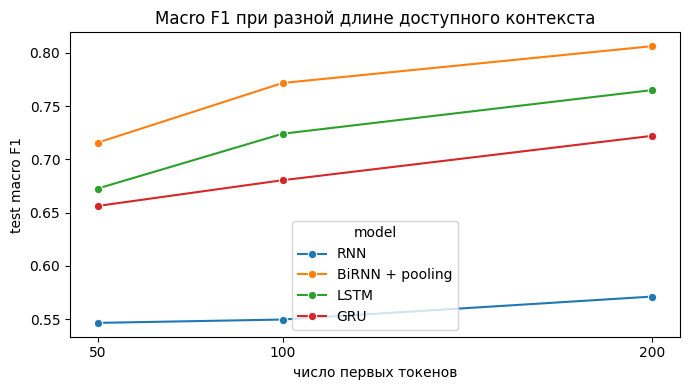

In [21]:
# Задание 4.6

models = {
    "RNN": rnn_model,
    "BiRNN + pooling": birnn_model,
    "LSTM": lstm_model,
    "GRU": gru_model,
}

rows = []
for context_len in [50, 100, 200]:
    context_dataset = ReviewDataset(test_df, stoi, max_len=context_len)
    loader = DataLoader(context_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_batch)
    for model_name, model in models.items():
        stats = run_epoch(model, loader, nn.CrossEntropyLoss())
        rows.append({
            "context_len": context_len,
            "model": model_name,
            "accuracy": stats["accuracy"],
            "macro_f1": stats["macro_f1"],
        })

context_results = pd.DataFrame(rows)
context_pivot = context_results.pivot(index="model", columns="context_len", values="macro_f1").loc[MODEL_ORDER]
context_pivot["drop_200_to_50"] = context_pivot[200] - context_pivot[50]
display(context_pivot.style.format("{:.4f}"))

plt.figure(figsize=(7, 4))
sns.lineplot(data=context_results, x="context_len", y="macro_f1", hue="model",
             hue_order=MODEL_ORDER, marker="o")
plt.xticks([50, 100, 200])
plt.title("Macro F1 при разной длине доступного контекста")
plt.xlabel("число первых токенов")
plt.ylabel("test macro F1")
plt.tight_layout()
plt.show()

## Задание 4.7. Сравните качество на коротких и длинных отзывах

Разделите тестовые отзывы по исходной длине:

- до 80 слов: `short`;
- от 81 до 200 слов: `medium`;
- более 200 слов: `long`.

Для RNN, BiRNN + pooling, LSTM и GRU:

1. получите предсказания на основном `test_loader`;
2. вычислите accuracy отдельно в каждой группе;
3. соберите таблицу и постройте группированную столбчатую диаграмму.

Важно: модель всё равно видит максимум 200 токенов. Группа `long` показывает поведение на исходно длинных документах, часть которых была обрезана.

Дополнительно найдите примеры, где каждая из более сложных моделей исправляет ошибку базовой RNN. Отдельно проверьте, бывают ли случаи, в которых BiRNN ошибается, а LSTM или GRU отвечает правильно.

length_group
short      260
medium    1512
long      1228
Name: count, dtype: int64


length_group,long,medium,short
model,,,
RNN,0.5513,0.5886,0.5731
BiRNN + pooling,0.7744,0.8280,0.8308
LSTM,0.7150,0.7983,0.8077
GRU,0.6938,0.7500,0.7846


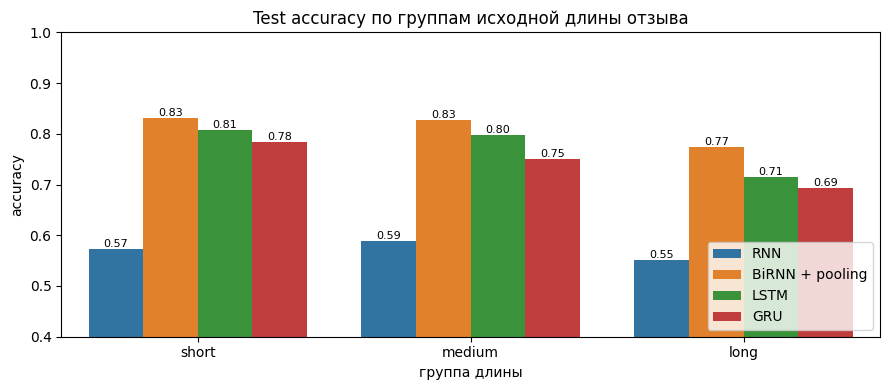

####################################################################################################
RNN ошиблась, BiRNN + pooling права: 1018 объектов
----------------------------------------------------------------------------------------------------
id=1443 | истинная: positive | RNN=negative, BiRNN + pooling=positive, LSTM=positive, GRU=positive | группа: short (37 слов)
The Animatrix: A Detective Story is very well planned and has a great storyline to go with it. Carrie-Anne Moss plays Trinity in this animated cartoon. I really like the 'Private Detective' ideas created by the Director.
----------------------------------------------------------------------------------------------------
id=1964 | истинная: positive | RNN=negative, BiRNN + pooling=positive, LSTM=positive, GRU=positive | группа: medium (107 слов)
Bedrooms and Hallways is the kind of film that makes you realize that the drama of life is hidden in the details. And that drama can be great fun too! Even though your own l

In [22]:
# Задание 4.7

analysis_df = test_df.copy()
analysis_df["n_words"] = analysis_df["text"].str.split().str.len()
analysis_df["length_group"] = pd.cut(
    analysis_df["n_words"],
    bins=[0, 80, 200, np.inf],
    labels=["short", "medium", "long"],
)
print(analysis_df["length_group"].value_counts().sort_index())

# 1. Предсказания всех моделей на основном test_loader
for model_name, model in models.items():
    _, pred, proba = predict_loader(model, test_loader)
    analysis_df[f"pred_{model_name}"] = pred
    analysis_df[f"conf_{model_name}"] = proba.max(axis=1)

# 2. Accuracy по группам длины
rows = []
for model_name in MODEL_ORDER:
    for group, part in analysis_df.groupby("length_group", observed=True):
        rows.append({
            "model": model_name,
            "length_group": group,
            "n": len(part),
            "accuracy": (part[f"pred_{model_name}"] == part["label"]).mean(),
        })
length_results = pd.DataFrame(rows)
display(length_results.pivot(index="model", columns="length_group", values="accuracy")
        .loc[MODEL_ORDER].style.format("{:.4f}"))

# 3. Группированная столбчатая диаграмма
plt.figure(figsize=(9, 4))
ax = sns.barplot(data=length_results, x="length_group", y="accuracy", hue="model", hue_order=MODEL_ORDER)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=8)
ax.set_ylim(0.4, 1.0)
ax.set_title("Test accuracy по группам исходной длины отзыва")
ax.set_xlabel("группа длины")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


# 4. Примеры исправлений
def is_correct(name):
    return analysis_df[f"pred_{name}"] == analysis_df["label"]


def show_examples(mask, title, conf_model, n=2, chars=400):
    subset = analysis_df[mask].sort_values(f"conf_{conf_model}", ascending=False)
    print("#" * 100)
    print(f"{title}: {len(subset)} объектов")
    for idx, row in subset.head(n).iterrows():
        preds = ", ".join(f"{m}={LABEL_NAMES[row[f'pred_{m}']]}" for m in MODEL_ORDER)
        print("-" * 100)
        print(f"id={idx} | истинная: {LABEL_NAMES[row['label']]} | {preds} | "
              f"группа: {row['length_group']} ({row['n_words']} слов)")
        print(HTML_RE.sub(" ", html.unescape(row["text"]))[:chars])


for model_name in ["BiRNN + pooling", "LSTM", "GRU"]:
    show_examples(~is_correct("RNN") & is_correct(model_name),
                  f"RNN ошиблась, {model_name} права", conf_model=model_name)

# Случаи, когда BiRNN ошибается, а LSTM или GRU отвечает правильно
birnn_wrong = ~is_correct("BiRNN + pooling")
print("\n")
print("BiRNN ошиблась, LSTM права:", (birnn_wrong & is_correct("LSTM")).sum())
print("BiRNN ошиблась, GRU права: ", (birnn_wrong & is_correct("GRU")).sum())
print("BiRNN ошиблась, права хотя бы одна из LSTM/GRU:",
      (birnn_wrong & (is_correct("LSTM") | is_correct("GRU"))).sum())
show_examples(birnn_wrong & is_correct("LSTM") & is_correct("GRU"),
              "BiRNN ошиблась, а LSTM и GRU обе правы", conf_model="GRU")

# Распределение таких случаев по длине
print("\nГруппы длины, где BiRNN ошиблась, а LSTM/GRU правы:")
print(analysis_df[birnn_wrong & (is_correct("LSTM") | is_correct("GRU"))]["length_group"]
      .value_counts().sort_index())

### Вывод по лабораторной работе 4

**Ваш вывод:**
В последовательности RNN → BiRNN + pooling → LSTM → GRU самый большой скачок качества даёт уход от простой RNN: все три улучшенные модели заметно превосходят базовую, а LSTM и GRU, оставаясь однонаправленными и используя только последнее состояние, выходят на уровень BiRNN + pooling (между собой LSTM и GRU отличаются незначительно, точный порядок — в `results_df`). Цена улучшений хорошо видна по рекуррентной части: при `hidden_dim=128` у RNN 33 024 параметра, у GRU в 3 раза больше (99 072), у LSTM в 4 раза больше (132 096), что точно соответствует числу блоков «вход + рекуррентная матрица + смещения» — 1, 3 и 4; во всей модели разница скромнее (≈2.59 → 2.66 → 2.69 млн), потому что основную массу занимает слой эмбеддингов, а время обучения у LSTM и GRU больше, чем у RNN, из-за дополнительных матричных умножений на каждом шаге. Сильнее всего от длины доступного контекста зависят модели, которые накапливают информацию по всему тексту (BiRNN + pooling, LSTM, GRU) — у них качество при 50 токенах падает заметнее, потому что из начала отзыва часто нельзя понять итоговую оценку; у простой RNN зависимость слабее и менее монотонна, так как она и на 200 токенах фактически опирается лишь на последние слова. По группам длины различия наиболее заметны на `medium` и `long` отзывах: на коротких текстах все модели справляются близко, а на длинных простая RNN теряет информацию из начала, тогда как ворота LSTM/GRU позволяют её сохранять. Это согласуется с назначением ворот: forget/update-ворота дают состоянию «пропускать» малозначимые слова и переносить оценочный сигнал на десятки шагов, а аддитивное обновление памяти смягчает затухание градиента. Пулинг BiRNN оказался полезен на отзывах, где сильные оценочные слова стоят в середине или где тональность смешанная, — max pooling вытягивает самый сильный сигнал из любой позиции. При этом однонаправленные LSTM и GRU нельзя считать прямой заменой двунаправленной модели: они не видят правый контекст токена и кодируют текст одним последним состоянием, а у BiRNN другой способ агрегации, поэтому сравнение отражает конкретные архитектуры, а не «ячейки вообще». Для этой задачи я бы выбрала GRU (или BiGRU с пулингом при наличии ресурсов): она даёт качество на уровне лучших моделей при меньшем числе параметров и времени, чем LSTM, а выбирать только по одной метрике качества нельзя — нужно учитывать стоимость обучения и инференса, стабильность и поведение на длинных текстах.

# Контрольные вопросы

1. Почему словарь должен строиться только по обучающей выборке?
2. Для чего нужны токены `<pad>` и `<unk>`?
3. Почему паддинг нельзя бездумно включать в рекуррентные вычисления? Как помогает `pack_padded_sequence`?
4. Что означает скрытое состояние $h_t$ простой RNN?
5. Почему простой RNN трудно сохранять информацию на большом числе шагов?
6. Чем затухающий градиент отличается от взрывающегося градиента?
7. Как устроена BiRNN и почему размер её выхода зависит от двух направлений?
8. В каких задачах нельзя использовать обратное направление BiRNN?
9. Чем mean pooling отличается от max pooling и какие признаки текста выделяет каждый способ?
10. Почему при пулинге необходимо исключать `<pad>` с помощью маски?
11. Почему объединённый эксперимент BiRNN + pooling не позволяет отдельно измерить вклад двунаправленности и пулинга?
12. Какие роли выполняют ворота забывания, входа и выхода в LSTM?
13. Чем состояние ячейки $C_t$ отличается от скрытого состояния $h_t$ в LSTM?
14. Какие ворота используются в GRU и как они влияют на обновление состояния?
15. Почему при одинаковом `hidden_dim` LSTM обычно имеет больше параметров, чем GRU, а GRU больше, чем простая RNN?
16. Почему для честного сравнения моделей следует сохранять одинаковые разбиения, словарь и протокол оценки?
17. Какие признаки переобучения можно увидеть на кривых train и validation loss?
18. Что именно проверяет эксперимент с 50, 100 и 200 токенами? Какие выводы по нему делать нельзя?
19. Почему accuracy на коротких и длинных текстах может различаться даже при сбалансированных классах?
20. В каких случаях вы предпочли бы GRU вместо LSTM?
21. Какие изменения эксперимента потребуются для многоклассовой классификации текста?

## Ответы на контрольные вопросы

1. **Почему словарь строится только по train?** Validation и test имитируют «будущие», невиданные данные. Если словарь (и частоты) собрать по ним, в модель утекает информация из оценочных выборок: редкие слова теста получат собственные индексы, и оценка качества станет оптимистично смещённой (data leakage).

2. **Зачем `<pad>` и `<unk>`?** `<pad>` выравнивает последовательности разной длины до одной длины внутри батча, чтобы их можно было уложить в тензор; благодаря `padding_idx` его эмбеддинг нулевой и не обучается. `<unk>` заменяет слова, которых нет в словаре (редкие или не встречавшиеся в train), чтобы любой текст можно было закодировать.

3. **Почему паддинг нельзя включать в рекуррентные вычисления?** RNN обработала бы паддинги как реальные шаги: итоговое состояние «уплыло» бы после десятков шагов по `<pad>`, причём по-разному в зависимости от того, с какими текстами объект попал в батч. `pack_padded_sequence` упаковывает батч так, что каждая последовательность обрабатывается ровно до своей длины, и `h_n` соответствует последнему настоящему токену.

4. **Что означает $h_t$ простой RNN?** Это вектор-«сводка» префикса $x_1, \dots, x_t$: состояние, в котором сеть хранит информацию о прочитанном к моменту $t$. Оно вычисляется по текущему входу и предыдущему состоянию: $h_t = \tanh(W_x x_t + W_h h_{t-1} + b)$.

5. **Почему простой RNN трудно хранить информацию на много шагов?** Состояние на каждом шаге полностью перезаписывается нелинейным преобразованием, и при обратном распространении градиент проходит через произведение якобианов $\prod W_h^\top \operatorname{diag}(\tanh')$. Обычно его норма экспоненциально убывает с расстоянием, так что сеть почти не получает сигнала для обучения дальним зависимостям.

6. **Затухающий vs взрывающийся градиент.** При затухании произведение якобианов стремится к нулю — далёкие шаги перестают влиять на обучение, модель «помнит» лишь последние токены. При взрыве произведение экспоненциально растёт — веса получают огромные обновления, loss скачет или становится `nan`. От взрыва помогает `clip_grad_norm_`, от затухания — архитектурные изменения (LSTM/GRU, residual-связи, attention).

7. **Как устроена BiRNN?** Две независимые RNN: прямая читает текст слева направо, обратная — справа налево. Для каждой позиции их состояния конкатенируются $o_t = [\overrightarrow{h_t}; \overleftarrow{h_t}]$, поэтому размер выхода равен $2 \cdot \text{hidden\_dim}$.

8. **Где нельзя использовать обратное направление?** Там, где в момент предсказания будущие токены недоступны: языковое моделирование и генерация текста (предсказание следующего токена), потоковое распознавание речи и онлайн-обработка в реальном времени, прогнозирование временных рядов, декодер в seq2seq.

9. **Mean vs max pooling.** Mean pooling усредняет состояния по всем позициям и отражает общую, «распределённую» тональность всего текста, но может размыть один яркий сигнал. Max pooling берёт максимум по каждому признаку и выделяет самые сильные локальные маркеры (например, «masterpiece», «awful»), где бы они ни стояли, но игнорирует их частоту и общий фон.

10. **Зачем маска при пулинге?** Без маски нули/выходы на позициях `<pad>` входили бы в среднее (занижая его) и могли бы стать максимумом в max pooling. Тогда представление текста зависело бы от длины других объектов в батче — один и тот же отзыв получал бы разные векторы.

11. **Почему эксперимент BiRNN + pooling не разделяет вклад факторов?** Одновременно изменены два фактора: двунаправленность и способ агрегации (последнее состояние → mean+max по всем позициям). Прирост качества может давать любой из них или их сочетание. Чтобы разделить вклад, нужна абляция: RNN + pooling, BiRNN + последние состояния, BiRNN + только mean, BiRNN + только max.

12. **Роли ворот LSTM.** Ворота забывания $f_t$ решают, какую часть старой памяти $C_{t-1}$ сохранить; входные ворота $i_t$ — какую часть нового кандидата $\widetilde{C}_t$ записать в память; выходные ворота $o_t$ — какую часть памяти выдать наружу в скрытое состояние $h_t$. Все ворота — сигмоиды со значениями в $(0, 1)$, работающие поэлементно.

13. **$C_t$ vs $h_t$ в LSTM.** $C_t$ — внутренняя долговременная память, обновляемая аддитивно ($f_t \odot C_{t-1} + i_t \odot \widetilde{C}_t$), поэтому по ней градиент проходит почти без затухания. $h_t = o_t \odot \tanh(C_t)$ — отфильтрованная «рабочая» выдача на текущем шаге, которая идёт в следующий слой, классификатор и в вычисление ворот на следующем шаге.

14. **Ворота GRU.** Reset-ворота $r_t$ определяют, сколько прошлого состояния использовать при вычислении кандидата $\widetilde{h}_t$ (позволяют «начать заново»). Update-ворота $z_t$ интерполируют между старым состоянием и кандидатом: $h_t = (1-z_t)\odot h_{t-1} + z_t \odot \widetilde{h}_t$ — при $z_t \approx 0$ состояние переносится без изменений, что и помогает хранить информацию долго.

15. **Почему параметров LSTM > GRU > RNN?** Каждое «преобразование» (матрица по входу, матрица по состоянию и смещения) содержит $H(E+H) + 2H$ параметров в PyTorch. У RNN одно такое преобразование, у GRU три ($r$, $z$, кандидат), у LSTM четыре ($f$, $i$, $o$, кандидат). При $E=H=128$ это 33 024, 99 072 и 132 096 параметров соответственно.

16. **Почему нужен одинаковый протокол?** Различия в метриках должны объясняться только архитектурой. Если менять разбиения, словарь, `MAX_LEN`, число эпох или критерий выбора чекпоинта, разница может возникнуть из-за более лёгкого теста, другой доли `<unk>` или большего бюджета обучения, и сравнение станет некорректным.

17. **Признаки переобучения на кривых.** Train loss продолжает снижаться, а validation loss перестаёт падать и начинает расти; растёт разрыв между train и validation; validation F1 выходит на плато или падает. Модель начинает запоминать обучающие примеры вместо обобщения.

18. **Что проверяет эксперимент с 50/100/200 токенами?** Он показывает, насколько качество уже обученной модели чувствительно к объёму доступного текста (сколько полезного сигнала лежит дальше первых 50/100 токенов). Нельзя делать вывод, что модель «использует дальние зависимости»: рост может объясняться просто большим количеством оценочных слов. Кроме того, модели обучались на 200 токенах, поэтому на коротких входах есть сдвиг распределения, а в тесте с 200 токенами длинные отзывы всё равно обрезаны.

19. **Почему accuracy на коротких и длинных текстах различается?** Баланс классов глобальный, но внутри групп длины он может нарушаться (например, негативные отзывы в среднем длиннее). Короткие тексты содержат мало сигнала и много неизвестных слов, а длинные — обрезаются до 200 токенов (теряется итоговая оценка), чаще содержат смешанную тональность, пересказ сюжета и сарказм; к тому же RNN-модели хуже хранят информацию на длинных последовательностях.

20. **Когда предпочесть GRU вместо LSTM?** Когда нужна более быстрая и лёгкая модель (меньше параметров, меньше памяти и время на шаг), когда данных немного и важно меньше переобучаться, или когда последовательности умеренной длины и качество GRU сопоставимо с LSTM. LSTM стоит выбрать, если нужна тонкая раздельная регуляция памяти на очень длинных последовательностях и вычислительные ресурсы позволяют.

21. **Что изменится для многоклассовой классификации?** Выходной слой `Linear(hidden, num_classes)` с числом классов $K > 2$; `CrossEntropyLoss` подходит без изменений (для дисбаланса — веса классов); стратифицированное разбиение по всем классам; метрики — macro/weighted F1, per-class отчёт и матрица ошибок $K \times K$; в анализе ошибок — какие классы путаются друг с другом. Для multi-label задачи вместо этого понадобились бы сигмоида на каждый класс и `BCEWithLogitsLoss`.